# NUEVA PROPUESTA 2/2 — Semana 10: continuar el modelo multitarea

Este notebook **no repite Semana 9**. Consume exclusivamente el checkpoint físico producido desde cero por `NUEVA_PROPUESTA_01_S9_entrenar_25D.ipynb`. No carga ningún checkpoint antiguo de Semana 10. Mantiene:

- `FundidoraBackbone`;
- CBAM;
- cabeza de detección.

Después crea desde cero las cabezas de clasificación, segmentación e instancias y ajusta el conjunto con rotación en milímetros. Mantiene EMA apagado y no activa el enderezado pélvico automático, que no mejoró las imágenes limpias.

In [1]:
import os
import sys
import json
import time
import subprocess
from pathlib import Path

def encontrar_raiz(inicio: Path) -> Path:
    for candidato in (inicio, *inicio.parents):
        if (candidato / "src" / "train_s10.py").exists() and (candidato / "README.md").exists():
            return candidato
    raise FileNotFoundError("No encontré la raíz del repositorio.")
ROOT = encontrar_raiz(Path.cwd().resolve())
os.chdir(ROOT)
os.environ["PYTHONUTF8"] = "1"
print("Raíz:", ROOT)
print("Python:", sys.version.split()[0], "| ejecutable:", sys.executable)

Raíz: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main
Python: 3.12.6 | ejecutable: e:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\.venv\Scripts\python.exe


## 1. Configuración conectada

`MODO_RAPIDO` debe tener el mismo valor usado en el notebook de Semana 9. La configuración completa carga únicamente el backbone, CBAM y detector físicos de Semana 9; las cabezas nuevas comienzan aleatorias. Usa rotación en milímetros desde la primera época de Semana 10, mantiene `EMA=0` y nunca consulta test para decidir cuándo parar.

In [15]:
MODO_RAPIDO = False
EXIGIR_GPU = True
CONSTRUIR_CACHE_SI_FALTA = True
EJECUTAR_ENTRENAMIENTO = True
EJECUTAR_EVALUACION_VALIDACION = True
EVALUAR_APORTACION_CBAM = True
EVALUAR_PRUEBA_FINAL = True  # cambia a True solo cuando validación ya cumpla 9/9
EJECUTAR_EVALUACION_PRUEBA = (not MODO_RAPIDO) and EVALUAR_PRUEBA_FINAL

CONTEXT = 1
SIZE = 384
SEED = 42
WEEK9_DIR = ROOT / "outputs" / "week9_25d"
SALIDA_DIR = ROOT / "outputs" / "s10" / "from_week9_25d"
SALIDA_DIR.mkdir(parents=True, exist_ok=True)
CACHE_ROOT = ROOT / "data" / "cache" / "s10"
CACHE_DIR = CACHE_ROOT / "cache_384"

if MODO_RAPIDO:
    WEEK9_CHECKPOINT = WEEK9_DIR / "smoke_week9_25d_rotacion_fisica_desde_cero_w8_e2_s42.pth"
    CHECKPOINT_INICIAL = None
    NOMBRE = "smoke_s10_desde_week9_fisica_w8_e2_s42"
    EPOCHS, BASE_CHANNELS, BATCH_SIZE = 2, 8, 4
    LR = 2e-3
    PER_EPOCH, EVAL_EVERY, FREEZE_WEEK9_EPOCHS = 100, 1, 1
    MAX_MINUTES = 15
    EPOCAS_MINIMAS, PACIENCIA, MEJORA_MINIMA = 0, 0, 0.002
    OBJETIVO_DICE, OBJETIVO_DICE_INSTANCIAS = None, None
    CASOS_VALIDACION = ["014"]
    CASOS_PRUEBA = ["007"]
else:
    WEEK9_CHECKPOINT = WEEK9_DIR / "week9_25d_rotacion_fisica_desde_cero_w32_e35_s42.pth"
    CHECKPOINT_INICIAL = None
    NOMBRE = "s10_desde_week9_rotacion_fisica_w32_e60_s42"
    EPOCHS, BASE_CHANNELS, BATCH_SIZE = 60, 32, 2
    LR = 2e-3
    PER_EPOCH, EVAL_EVERY, FREEZE_WEEK9_EPOCHS = 2500, 5, 5
    MAX_MINUTES = None
    EPOCAS_MINIMAS, PACIENCIA, MEJORA_MINIMA = 25, 4, 0.002
    OBJETIVO_DICE, OBJETIVO_DICE_INSTANCIAS = 0.85, 0.85
    CASOS_VALIDACION = []
    CASOS_PRUEBA = []

CHECKPOINT = SALIDA_DIR / f"{NOMBRE}.pth"
HISTORIAL = CHECKPOINT.with_suffix(".json")
VALIDACION = SALIDA_DIR / f"{NOMBRE}_val.json"
PRUEBA = SALIDA_DIR / f"{NOMBRE}_test.json"
LOG_ENTRENAMIENTO = SALIDA_DIR / f"{NOMBRE}_train.log"
LOG_EVALUACION_VAL = SALIDA_DIR / f"{NOMBRE}_eval_val.log"
LOG_EVALUACION_TEST = SALIDA_DIR / f"{NOMBRE}_eval_test.log"
print("Checkpoint Semana 9:", WEEK9_CHECKPOINT)
print("Continuación desde:", CHECKPOINT_INICIAL or "pesos de Semana 9")
print("Nuevo checkpoint Semana 10:", CHECKPOINT)
print("Parada temprana:", {"min_epocas": EPOCAS_MINIMAS, "paciencia": PACIENCIA,
                              "min_delta": MEJORA_MINIMA, "objetivo_semantico": OBJETIVO_DICE,
                              "objetivo_instancias": OBJETIVO_DICE_INSTANCIAS})

Checkpoint Semana 9: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\week9_25d\week9_25d_rotacion_fisica_desde_cero_w32_e35_s42.pth
Continuación desde: pesos de Semana 9
Nuevo checkpoint Semana 10: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\from_week9_25d\s10_desde_week9_rotacion_fisica_w32_e60_s42.pth
Parada temprana: {'min_epocas': 25, 'paciencia': 4, 'min_delta': 0.002, 'objetivo_semantico': 0.85, 'objetivo_instancias': 0.85}


In [3]:
import torch
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))
elif EXIGIR_GPU: raise RuntimeError("No hay GPU CUDA disponible.")

PyTorch: 2.11.0+cu128
CUDA disponible: True
GPU: NVIDIA GeForce GTX 1650 SUPER


## 2. Verificación obligatoria del checkpoint de Semana 9

In [4]:
if not WEEK9_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"Falta {WEEK9_CHECKPOINT}. Ejecuta primero NUEVA_PROPUESTA_01 de Semana 9 "
        f"con MODO_RAPIDO={MODO_RAPIDO}."
    )
week9 = torch.load(WEEK9_CHECKPOINT, map_location="cpu", weights_only=False)
comprobacion = {
    "in_channels": week9.get("in_channels"), "context": week9.get("context"),
    "base_channels": week9.get("base_channels"), "canonical": week9.get("canonical"),
    "best_epoch": week9.get("best_epoch"), "best_val_f1": week9.get("best_val_f1"),
}
display(comprobacion)
assert int(week9["in_channels"]) == 3
assert int(week9["context"]) == CONTEXT
assert int(week9["base_channels"]) == BASE_CHANNELS
assert bool(week9["canonical"])
assert bool(week9["aug_mm"]) and float(week9["aug_rot_deg"]) == 35.0
assert any(k.startswith("backbone.") for k in week9["model"])
assert any(k.startswith("detection_head.") for k in week9["model"])
print("OK: Semana 9 es compatible; no se continuará desde pesos aleatorios.")
if CHECKPOINT_INICIAL is not None:
    if not CHECKPOINT_INICIAL.exists():
        raise FileNotFoundError(f"Falta el checkpoint anterior: {CHECKPOINT_INICIAL}")
    anterior = torch.load(CHECKPOINT_INICIAL, map_location="cpu", weights_only=False)
    assert int(anterior["in_channels"]) == 3
    assert int(anterior["base_channels"]) == BASE_CHANNELS
    assert bool(anterior["canonical"])
    print("OK: se cargaría un checkpoint de Semana 10 completo.")

{'in_channels': 3,
 'context': 1,
 'base_channels': 32,
 'canonical': True,
 'best_epoch': 33,
 'best_val_f1': 0.5613660618996799}

OK: Semana 9 es compatible; no se continuará desde pesos aleatorios.


In [5]:
def ejecutar_visible(comando, titulo, log_path=None):
    print(f"\n=== {titulo} ===")
    print(" ".join(map(str, comando)))
    inicio = time.time()
    with subprocess.Popen(comando, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                          text=True, encoding="utf-8", errors="replace", bufsize=1) as proceso:
        lineas = []
        for linea in proceso.stdout:
            print(linea, end=""); lineas.append(linea)
        codigo = proceso.wait()
    if log_path is not None: log_path.write_text("".join(lineas), encoding="utf-8")
    print(f"=== finalizó con código {codigo} en {(time.time()-inicio)/60:.1f} min ===")
    if codigo != 0: raise RuntimeError(f"El comando terminó con código {codigo}.")

## 3. Caché completo de Semana 10

In [6]:
casos_cache = sorted(CACHE_DIR.glob("*.npz")) if CACHE_DIR.exists() else []
print(f"Caché actual: {len(casos_cache)} casos")
if len(casos_cache) < 100:
    if not CONSTRUIR_CACHE_SI_FALTA:
        raise FileNotFoundError("Caché incompleto y CONSTRUIR_CACHE_SI_FALTA=False.")
    ejecutar_visible([sys.executable, "src/build_case_cache.py", "--sizes", str(SIZE),
                      "--modes", "stretch", "--workers", "4"], "Construcción caché Semana 10")
    casos_cache = sorted(CACHE_DIR.glob("*.npz"))
if len(casos_cache) < 100: raise RuntimeError(f"Caché incompleto: {len(casos_cache)}/100")
print("Caché listo:", CACHE_DIR)

Caché actual: 100 casos
Caché listo: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\data\cache\s10\cache_384


## 4. Semana 10 limpia desde el checkpoint físico de Semana 9

No se usa `--resume`. Se cargan solamente backbone, CBAM y detector desde Semana 9 mediante `--week9-checkpoint`; las demás cabezas nacen en esta semana. El entrenamiento usa `--aug-mm`, `EMA=0` y conserva separados todos los modelos anteriores.

In [7]:
comando = [
    sys.executable, "src/train_s10.py", "--cache-root", str(CACHE_ROOT),
    "--size", str(SIZE), "--epochs", str(EPOCHS),
    "--lr", str(LR),
    "--base-channels", str(BASE_CHANNELS), "--cbam", "1",
    "--secondary-weight", "3", "--augment", "--cosine",
    "--batch-size", str(BATCH_SIZE), "--per-epoch", str(PER_EPOCH),
    "--eval-every", str(EVAL_EVERY), "--context", str(CONTEXT),
    "--seed", str(SEED), "--aug-geo", "1.0", "--aug-rot-deg", "35",
    "--canonical", "--aug-mm", "--disable-cudnn",
    "--early-stopping-min-epochs", str(EPOCAS_MINIMAS),
    "--early-stopping-patience", str(PACIENCIA),
    "--early-stopping-min-delta", str(MEJORA_MINIMA),
    "--early-stopping-metric", "instance_dice",
    "--checkpoint-metric", "instance_dice",
    "--output", str(CHECKPOINT),
]
if CHECKPOINT_INICIAL is not None:
    comando.extend(["--resume", str(CHECKPOINT_INICIAL)])
else:
    comando.extend(["--week9-checkpoint", str(WEEK9_CHECKPOINT),
                    "--freeze-week9-epochs", str(FREEZE_WEEK9_EPOCHS)])
if OBJETIVO_DICE is not None: comando.extend(["--stop-dice", str(OBJETIVO_DICE)])
if OBJETIVO_DICE_INSTANCIAS is not None:
    comando.extend(["--stop-instance-dice", str(OBJETIVO_DICE_INSTANCIAS)])
if MAX_MINUTES is not None: comando.extend(["--max-minutes", str(MAX_MINUTES)])
if EJECUTAR_ENTRENAMIENTO:
    titulo = "Semana 10 física desde checkpoint S10" if CHECKPOINT_INICIAL else "Semana 10 limpia desde Semana 9 física"
    ejecutar_visible(comando, titulo, LOG_ENTRENAMIENTO)
elif CHECKPOINT.exists():
    print("Se reutiliza:", CHECKPOINT)
else:
    raise FileNotFoundError("No existe el checkpoint físico y EJECUTAR_ENTRENAMIENTO=False.")


=== Semana 10 limpia desde Semana 9 física ===
e:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\.venv\Scripts\python.exe src/train_s10.py --cache-root E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\data\cache\s10 --size 384 --epochs 60 --lr 0.002 --base-channels 32 --cbam 1 --secondary-weight 3 --augment --cosine --batch-size 2 --per-epoch 2500 --eval-every 5 --context 1 --seed 42 --aug-geo 1.0 --aug-rot-deg 35 --canonical --aug-mm --disable-cudnn --early-stopping-min-epochs 25 --early-stopping-patience 4 --early-stopping-min-delta 0.002 --early-stopping-metric instance_dice --checkpoint-metric instance_dice --output E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\from_week9_25d\s10_desde_week9_rotacion_fisica_w32_e60_s42.pth --week9-checkpoint E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\week9_25d\week9_25d_rotacion_fisica_desde_cero_w32_e35_s42.pth --freeze-week9-epochs 5 --stop-dice 0.85 --stop-instance-dice 0.85
Casos: train=70 va

## 5. Prueba de trazabilidad

In [8]:
resultado = torch.load(CHECKPOINT, map_location="cpu", weights_only=False)
transferencia = resultado.get("week9_transfer")
assert transferencia is not None, "El checkpoint no registra transferencia desde Semana 9."
assert Path(transferencia["path"]).resolve() == WEEK9_CHECKPOINT.resolve()
assert transferencia["backbone_tensors"] > 0
assert transferencia["detection_tensors"] > 0
assert bool(transferencia["aug_mm"]) and float(transferencia["aug_rot_deg"]) == 35.0
assert int(resultado["in_channels"]) == 3
assert bool(resultado["aug_mm"]) and not bool(resultado["normalizar"])
assert resultado.get("continued_from") is None, "Esta corrida limpia no debe continuar desde Semana 10."
if CHECKPOINT_INICIAL is not None:
    continuacion = resultado.get("continued_from")
    assert continuacion is not None, "No se registró el checkpoint de continuación."
    assert Path(continuacion["path"]).resolve() == CHECKPOINT_INICIAL.resolve()
    print("Continuación registrada:", continuacion["path"])
no_finitos = sum(int((~torch.isfinite(v)).sum()) for v in resultado["model"].values()
                 if torch.is_tensor(v) and v.is_floating_point())
print("Transferencia registrada:", transferencia)
print("Valores no finitos:", no_finitos)
assert no_finitos == 0
print("OK: la salida de Semana 10 demuestra de qué checkpoint de Semana 9 provino.")

Transferencia registrada: {'path': 'E:\\Proyecto_2_Analytics\\proyecto2-analitica-datos-main\\outputs\\week9_25d\\week9_25d_rotacion_fisica_desde_cero_w32_e35_s42.pth', 'best_epoch': 33, 'best_val_f1': 0.5613660618996799, 'backbone_tensors': 51, 'detection_tensors': 8, 'in_channels': 3, 'canonical': True, 'aug_geo': 1.0, 'aug_rot_deg': 35.0, 'aug_mm': True}
Valores no finitos: 0
OK: la salida de Semana 10 demuestra de qué checkpoint de Semana 9 provino.


,epoch,loss,score,early_stopping_bad_evaluations,early_stopping_metric,semantic_dice_target_reached,instance_dice_target_reached,all_dice_targets_reached,classification_f1_macro,classification_auc_macro,...,detection_map50,detection_map50_95,segmentation_dice_macro,segmentation_iou_macro,instance_dice_matched,instance_iou_matched,instance_semantic_cc_dice_matched,instance_semantic_cc_iou_matched,instance_direct_dice_matched,instance_direct_iou_matched
1,5,1.200210,2.303436,0,instance_dice,True,False,False,0.902109,0.952183,...,0.693920,0.512103,0.861111,0.761255,0.748405,0.664287,0.726854,0.656535,0.748405,0.664287
2,10,0.973133,2.448747,0,instance_dice,True,False,False,0.957028,0.981919,...,0.740507,0.601761,0.922547,0.857817,0.785693,0.708678,0.754027,0.696160,0.785693,0.708678
3,15,0.839932,2.518524,0,instance_dice,True,False,False,0.944193,0.983136,...,0.791625,0.622182,0.929567,0.869328,0.797331,0.725869,0.771909,0.713324,0.797331,0.725869
4,20,0.791987,2.699801,0,instance_dice,True,False,False,0.971481,0.990143,...,0.909277,0.800696,0.955745,0.916031,0.834779,0.765368,0.785320,0.732955,0.834779,0.765368
5,25,0.731406,2.698688,0,instance_dice,True,True,True,0.972164,0.992111,...,0.886321,0.794938,0.960078,0.923707,0.852289,0.779752,0.792703,0.741906,0.852289,0.779752


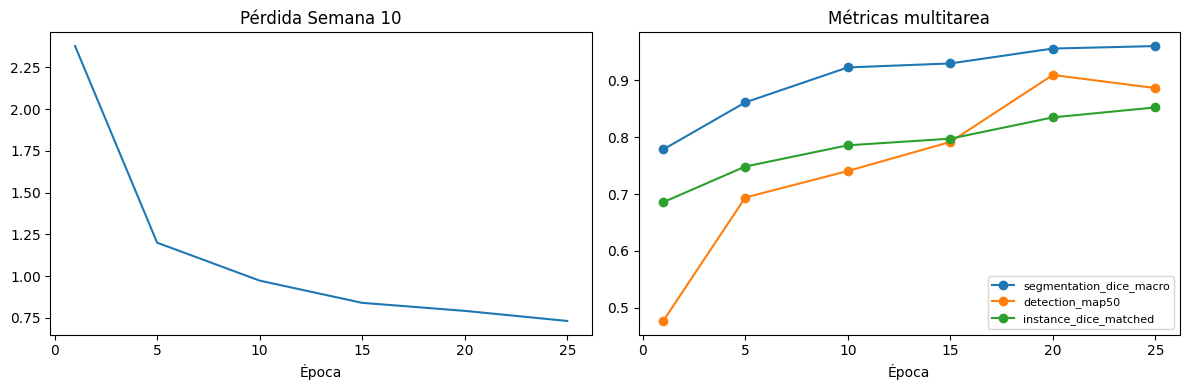

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
historial = json.loads(HISTORIAL.read_text(encoding="utf-8"))
df = pd.DataFrame(historial["history"])
display(df.tail())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(df.epoch, df.loss); axes[0].set(title="Pérdida Semana 10", xlabel="Época")
for clave in ["segmentation_dice_macro", "detection_map50", "instance_dice_matched"]:
    axes[1].plot(df.epoch, df[clave], marker="o", label=clave)
axes[1].set(title="Métricas multitarea", xlabel="Época"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Evaluación final: validación y prueba

Durante el entrenamiento se usa **validación** para escoger el mejor checkpoint. Aquí se mide primero sobre los 15 pacientes de validación y, con la configuración ya congelada, una sola vez sobre los 15 pacientes de **test**. Las métricas de test son las que representan mejor el rendimiento final ante imágenes no vistas.

In [16]:
def evaluar_split(split, salida, log, casos, ejecutar):
    comando_eval = [
        sys.executable, "src/evaluate_volumes.py", "--checkpoint", str(CHECKPOINT),
        "--cache-dir", str(CACHE_DIR), "--split", split,
        "--batch-size", str(BATCH_SIZE), "--tta", "--output", str(salida),
    ]
    if casos: comando_eval.extend(["--cases", *casos])
    if ejecutar:
        ejecutar_visible(comando_eval, f"Evaluación volumétrica {split}", log)
    elif salida.exists():
        print(f"Se reutiliza {split}:", salida)
    else:
        print(f"Evaluación {split} pendiente:", salida)

evaluar_split("val", VALIDACION, LOG_EVALUACION_VAL, CASOS_VALIDACION,
              EJECUTAR_EVALUACION_VALIDACION)
evaluar_split("test", PRUEBA, LOG_EVALUACION_TEST, CASOS_PRUEBA,
              EJECUTAR_EVALUACION_PRUEBA)

metricas_clave = [
    "classification_f1_macro", "classification_auc_macro",
    "detection_iou_mean", "detection_map50", "detection_map50_95",
    "segmentation_dice_macro", "segmentation_iou_macro",
    "instance_dice_matched", "instance_iou_matched",
]
filas = []
for split, ruta in (("validación", VALIDACION), ("prueba", PRUEBA)):
    if not ruta.exists(): continue
    evaluacion = json.loads(ruta.read_text(encoding="utf-8"))
    for subconjunto in ("todo", "con_hueso"):
        resumen = evaluacion["subsets"][subconjunto]
        filas.append({"conjunto": split, "subconjunto": subconjunto,
                      **{m: resumen.get(m) for m in metricas_clave}})
if filas:
    display(pd.DataFrame(filas).set_index(["conjunto", "subconjunto"]).round(4))
else:
    print("Todavía no hay resultados volumétricos para comparar.")


=== Evaluación volumétrica val ===
e:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\.venv\Scripts\python.exe src/evaluate_volumes.py --checkpoint E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\from_week9_25d\s10_desde_week9_rotacion_fisica_w32_e60_s42.pth --cache-dir E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\data\cache\s10\cache_384 --split val --batch-size 2 --tta --output E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\from_week9_25d\s10_desde_week9_rotacion_fisica_w32_e60_s42_val.json
15 casos de val | dispositivo cuda | TTA=True | segundo pase=False | normalizar=False
  1/15 caso 014: 298 cortes (100 s)
  2/15 caso 019: 350 cortes (189 s)
  3/15 caso 024: 350 cortes (279 s)
  4/15 caso 027: 313 cortes (359 s)
  5/15 caso 033: 365 cortes (456 s)
  6/15 caso 044: 409 cortes (567 s)
  7/15 caso 050: 326 cortes (654 s)
  8/15 caso 057: 341 cortes (742 s)
  9/15 caso 060: 333 cortes (830 s)
  10/15 caso 067: 369 cortes (927 s)
 

classification_f1_macro  classification_auc_macro  \
conjunto   subconjunto                                                      
validación todo                          0.9709                    0.9946   
           con_hueso                     0.9712                    0.9836   
prueba     todo                          0.9637                    0.9918   
           con_hueso                     0.9640                    0.9688   

                        detection_iou_mean  detection_map50  \
conjunto   subconjunto                                        
validación todo                     0.9120           0.9192   
           con_hueso                0.9120           0.9223   
prueba     todo                     0.9156           0.9294   
           con_hueso                0.9156           0.9326   

                        detection_map50_95  segmentation_dice_macro  \
conjunto   subconjunto                                                
validación todo                     0.8381                   0.9635   
           con_hueso                0.8420                   0.9644   
prueba     todo                     0.8493                   0.9650   
           con_hueso                0.8535                   0.9669   

                        segmentation_iou_macro  instance_dice_matched  \
conjunto   subconjunto                                                  
validación todo                         0.9300                 0.8558   
           con_hueso                    0.9317                 0.8558   
prueba     todo                         0.9326                 0.8642   
           con_hueso                    0.9360                 0.8642   

                        instance_iou_matched  
conjunto   subconjunto                        
validación todo                       0.7900  
           con_hueso                  0.7900  
prueba     todo                       0.8017  
           con_hueso                  0.8017

## Flujo conseguido

```text
Semana 9 2.5D
  checkpoint: backbone + CBAM + detector
                ↓ carga verificada
Semana 10 2.5D
  mismos módulos + clasificación + segmentación
```

La corrida anterior 2.5D desde cero permanece intacta como ablación sin transferencia. El historial de entrenamiento conserva la pérdida de `train` y las métricas de selección en `val`; los archivos `_val.json` y `_test.json` contienen la evaluación volumétrica final por separado.

## Auditoría de orientación y rotación física (artículo del profesor)

Esta sección **no reentrena** y nunca usa test. Primero estresa validación con un giro real en milímetros (`rotmm`) y después permite que la normalización por simetría pélvica lo corrija. La cabecera MHA se valida mediante productos punto y cruz. El método se abstiene si la mejora es pequeña o existe riesgo de recorte.

Activa `EJECUTAR_AUDITORIA_ROTACION` cuando quieras correr la comparación completa.

In [18]:
EJECUTAR_AUDITORIA_ROTACION = True  # True: solo validación; no modifica el checkpoint
ROTACION_DIR = ROOT / 'outputs' / 's10' / 'auditoria_rotacion_fisica'
ROTACION_DIR.mkdir(parents=True, exist_ok=True)

experimentos_rotacion = [
    ('limpio_normalizado', None, True),
    ('rotmm30_sin_corregir', 'rotmm=30', False),
    ('rotmm30_corregido', 'rotmm=30', True),
    ('rotmm60_sin_corregir', 'rotmm=60', False),
    ('rotmm60_corregido', 'rotmm=60', True),
]

if EJECUTAR_AUDITORIA_ROTACION:
    for nombre, stress, normalizar in experimentos_rotacion:
        salida = ROTACION_DIR / f'{nombre}.json'
        comando = [sys.executable, 'src/evaluate_volumes.py', '--checkpoint', str(CHECKPOINT),
                   '--cache-dir', str(CACHE_DIR), '--split', 'val', '--batch-size',
                   str(BATCH_SIZE), '--tta', '--output', str(salida)]
        if stress: comando.extend(['--stress', stress])
        comando.append('--normalizar' if normalizar else '--no-normalizar')
        ejecutar_visible(comando, f'Rotación física: {nombre}', ROTACION_DIR / f'{nombre}.log')
else:
    print('Auditoría preparada. Cambia EJECUTAR_AUDITORIA_ROTACION a True para ejecutarla.')


=== Rotación física: limpio_normalizado ===
e:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\.venv\Scripts\python.exe src/evaluate_volumes.py --checkpoint E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\from_week9_25d\s10_desde_week9_rotacion_fisica_w32_e60_s42.pth --cache-dir E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\data\cache\s10\cache_384 --split val --batch-size 2 --tta --output E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\auditoria_rotacion_fisica\limpio_normalizado.json --normalizar
15 casos de val | dispositivo cuda | TTA=True | segundo pase=False | normalizar=True
    normalización 014: ángulo=-6.0° aceptada=False (field_of_view_crop_risk)
  1/15 caso 014: 298 cortes (78 s)
    normalización 019: ángulo=-1.0° aceptada=False (angle_below_5deg)
  2/15 caso 019: 350 cortes (169 s)
    normalización 024: ángulo=+3.0° aceptada=False (angle_below_5deg)
  3/15 caso 024: 350 cortes (260 s)
    normalización 027: ángulo=-1.0°

## 7. Publicación del modelo final

Esta celda se ejecuta al terminar el flujo. Verifica que el checkpoint y la evaluación de validación correspondan entre sí y publica una copia con nombre estable. El checkpoint original se conserva.

In [20]:
import hashlib
import shutil

if not CHECKPOINT.exists():
    raise FileNotFoundError(f'No se puede publicar: falta el checkpoint {CHECKPOINT}')
if not HISTORIAL.exists():
    raise FileNotFoundError(f'No se puede publicar: falta el historial {HISTORIAL}')
if not VALIDACION.exists():
    raise FileNotFoundError(
        f'No se puede publicar todavía: falta la evaluación de validación {VALIDACION}'
    )

evaluacion_final = json.loads(VALIDACION.read_text(encoding='utf-8'))
checkpoint_guardado = evaluacion_final['checkpoint']
if isinstance(checkpoint_guardado, list):
    if len(checkpoint_guardado) != 1:
        raise RuntimeError('La publicación final requiere exactamente un checkpoint.')
    checkpoint_guardado = checkpoint_guardado[0]
checkpoint_evaluado = Path(checkpoint_guardado).resolve()
if checkpoint_evaluado != CHECKPOINT.resolve():
    raise RuntimeError(
        f'La validación pertenece a otro checkpoint: {checkpoint_evaluado}'
    )

modelo_verificado = torch.load(CHECKPOINT, map_location='cpu', weights_only=False)
no_finitos_final = sum(
    int((~torch.isfinite(valor)).sum())
    for valor in modelo_verificado['model'].values()
    if torch.is_tensor(valor) and valor.is_floating_point()
)
if no_finitos_final:
    raise RuntimeError(f'El checkpoint contiene {no_finitos_final} valores no finitos.')

nombre_publicado = ('smoke_modelo_final_semana10.pth' if MODO_RAPIDO
                    else 'modelo_final_semana10.pth')
MODELO_FINAL = SALIDA_DIR / nombre_publicado
temporal = MODELO_FINAL.with_suffix('.pth.tmp')
shutil.copy2(CHECKPOINT, temporal)
os.replace(temporal, MODELO_FINAL)  # reemplazo atómico: nunca deja un .pth parcial
sha256 = hashlib.sha256(MODELO_FINAL.read_bytes()).hexdigest()

MANIFIESTO_FINAL = MODELO_FINAL.with_suffix('.json')
manifiesto = {
    'modelo_final': str(MODELO_FINAL.resolve()),
    'checkpoint_origen': str(CHECKPOINT.resolve()),
    'sha256': sha256,
    'bytes': MODELO_FINAL.stat().st_size,
    'historial': str(HISTORIAL.resolve()),
    'evaluacion_validacion': str(VALIDACION.resolve()),
    'evaluacion_prueba': str(PRUEBA.resolve()) if PRUEBA.exists() else None,
    'mejor_validacion_entrenamiento': modelo_verificado.get('best_validation'),
}
MANIFIESTO_FINAL.write_text(json.dumps(manifiesto, indent=2), encoding='utf-8')

print('MODELO FINAL GUARDADO Y VERIFICADO')
print('Modelo:', MODELO_FINAL)
print('Manifiesto:', MANIFIESTO_FINAL)
print('SHA-256:', sha256)

MODELO FINAL GUARDADO Y VERIFICADO
Modelo: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\from_week9_25d\modelo_final_semana10.pth
Manifiesto: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\from_week9_25d\modelo_final_semana10.json
SHA-256: ed71a7c626eb7e0d6348a1e0535ca852c60c4b9371ce8aa8cf3b608a08dccfb2


## 8. Aportación final de CBAM por cabeza

Esta última sección reutiliza las métricas volumétricas de validación con CBAM y ejecuta únicamente el pase adicional con CBAM puenteado. Reporta clasificación, detección y segmentación, además de un score general con igual peso por cabeza. **Nunca consulta test**.

In [21]:
APORTACION_CBAM_S10 = SALIDA_DIR / f'{NOMBRE}_cbam_aportacion.json'
comando_cbam_s10 = [
    sys.executable, 'src/analizar_aportacion_cbam_s10.py',
    '--checkpoint', str(CHECKPOINT), '--cache-dir', str(CACHE_DIR),
    '--with-cbam-json', str(VALIDACION), '--batch-size', str(BATCH_SIZE),
    '--output', str(APORTACION_CBAM_S10),
]
if EVALUAR_APORTACION_CBAM:
    if not VALIDACION.exists():
        raise FileNotFoundError('Primero debe existir la evaluación de validación con CBAM.')
    ejecutar_visible(comando_cbam_s10, 'Aportación CBAM por cabeza — Semana 10')
else:
    print('Ablación CBAM omitida. Activa EVALUAR_APORTACION_CBAM para ejecutarla.')


=== Aportación CBAM por cabeza — Semana 10 ===
e:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\.venv\Scripts\python.exe src/analizar_aportacion_cbam_s10.py --checkpoint E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\from_week9_25d\s10_desde_week9_rotacion_fisica_w32_e60_s42.pth --cache-dir E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\data\cache\s10\cache_384 --with-cbam-json E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\from_week9_25d\s10_desde_week9_rotacion_fisica_w32_e60_s42_val.json --batch-size 2 --output E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\from_week9_25d\s10_desde_week9_rotacion_fisica_w32_e60_s42_cbam_aportacion.json
  sin CBAM 1/15: caso 014
  sin CBAM 2/15: caso 019
  sin CBAM 3/15: caso 024
  sin CBAM 4/15: caso 027
  sin CBAM 5/15: caso 033
  sin CBAM 6/15: caso 044
  sin CBAM 7/15: caso 050
  sin CBAM 8/15: caso 057
  sin CBAM 9/15: caso 060
  sin CBAM 10/15: caso 067
  sin CBAM 11/15: